# 02 · Transformer Encoder–Decoder — huấn luyện từ đầu

Cài đặt **từ đầu bằng PyTorch** (file `envi_lib/models.py`): Multi-Head Attention, Positional Encoding, khối
Encoder/Decoder với residual + LayerNorm, mặt nạ nhân quả, embedding dùng chung (weight tying).
Huấn luyện: AdamW (β=0.9/0.98) + lịch học inverse-sqrt có warmup, label smoothing 0.1, dropout 0.3,
batch theo số token, early stopping theo BLEU dev. Giải mã: greedy và beam search (tự cài).

**Thí nghiệm:** mô hình chính `tf_base` (6+6 lớp) và 3 biến thể (ablation): 3+3 lớp · positional encoding học được · Post-LN.
Mô hình chính được dịch với beam = 1, 2, 4, 8 để phân tích ảnh hưởng của beam size.

⏱️ Thời gian ước tính (bản thật, mỗi thí nghiệm): A100 ≈ 30–60 phút · L4 ≈ 1–2 giờ · T4 ≈ 2–4 giờ.

> **Quy trình chống lỗi:** luôn chạy với `DRY_RUN = True` trước (vài phút, dữ liệu và mô hình tí hon, đi qua **mọi**
> dòng code). Khi không còn lỗi nào, đổi `DRY_RUN = False` rồi chọn **Runtime → Run all** để chạy thật.
> Kết quả chạy thử nằm riêng trong thư mục `dryrun/`, không lẫn với kết quả thật.

> **Nếu Colab mất kết nối / hết phiên:** mở lại notebook, **Run all**. Huấn luyện tự tiếp tục từ checkpoint gần nhất
> (lưu mỗi vài trăm bước trên Drive). Bản dịch đã sinh từ đúng checkpoint sẽ không bị dịch lại.

In [1]:
#@title ⚙️ Tham số
DRY_RUN = False
RUN_ABLATIONS = True          # False: chỉ chạy mô hình chính
BEAMS_MAIN = [1, 2, 4, 8]     # beam size dùng cho mô hình chính
BEAM_DEFAULT = 4              # beam size cho các biến thể
TIME_BUDGET_HOURS = None      # vd 3.5: tự dừng an toàn sau 3,5 giờ; chạy lại sẽ tiếp tục

In [2]:
#@title 🔧 Kết nối Google Drive + nạp thư viện `envi_lib`
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
PROJECT_DIR = os.environ.get("ENVI_PROJECT_DIR", "/content/drive/MyDrive/NLP_Final_EnVi")
if not os.path.exists(os.path.join(PROJECT_DIR, "envi_lib", "__init__.py")):
    raise FileNotFoundError(f"Chưa có thư viện ở {PROJECT_DIR}/envi_lib — hãy chạy notebook 00_cai_dat.ipynb trước.")
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
from envi_lib.common import (Paths, set_seed, get_device, pick_amp_dtype, autocast_ctx, gpu_info, peak_gpu_mem_gb,
                             reset_peak_mem, free_memory, count_params, disk_free_gb, save_predictions,
                             prediction_is_current, save_json, load_json, read_lines, write_lines, fmt_seconds,
                             bf16_supported, check_lib_version, now_str)
check_lib_version("1.0.0")
paths = Paths(PROJECT_DIR, dry_run=DRY_RUN).make_all()
DEVICE = get_device()
print(f"📁 {paths.root}   |   DRY_RUN = {DRY_RUN}   |   thiết bị: {gpu_info()}")

Mounted at /content/drive
📁 /content/drive/MyDrive/NLP_Final_EnVi   |   DRY_RUN = False   |   thiết bị: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True}


In [3]:
%pip install -q sacrebleu sacremoses sentencepiece

In [4]:
import math, time, json, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from functools import partial
from envi_lib import data as D, models as MD, decoding as DEC, metrics as M, selftest
from envi_lib.train import TrainConfig, Trainer

AMP = pick_amp_dtype("auto")
print("GPU:", gpu_info(), "| autocast:", AMP)
if DEVICE.type != "cuda":
    if DRY_RUN:
        print("⚠️  Không có GPU — DRY_RUN vẫn chạy trên CPU (chậm hơn).")
    else:
        raise RuntimeError("Cần GPU: Runtime → Change runtime type → GPU")
print("Drive còn trống:", disk_free_gb(paths.root), "GB")
assert selftest.run_all(skip_slow=True), "Kiểm thử nhanh thất bại"

data = D.load_all_clean(paths, DRY_RUN)
tok = D.SpmTokenizer(paths.spm_model)
MAX_TOK = 150
tr_src, tr_tgt, n_drop = D.filter_by_token_len(tok.encode(data["train"][0]), tok.encode(data["train"][1]), MAX_TOK, MAX_TOK)
dev_src_txt, dev_ref = data["dev"]
test_src_txt, test_ref = data["test"]
dev_src_ids, dev_tgt_ids = tok.encode(dev_src_txt), tok.encode(dev_ref)
print(f"Train: {len(tr_src):,} cặp (bỏ {n_drop} cặp > {MAX_TOK} token) | dev: {len(dev_ref):,} | test: {len(test_ref):,} | vocab: {tok.vocab_size}")

GPU: {'cuda': True, 'torch': '2.11.0+cu130', 'name': 'NVIDIA L4', 'total_gb': 22.0, 'bf16': True} | autocast: torch.bfloat16
Drive còn trống: 183.6 GB
✅ Chuẩn hoá Unicode tiếng Việt
✅ Làm sạch dòng (HTML + detokenize)
✅ Batch theo số token, xác định theo epoch
✅ Ghép batch Seq2Seq / GPT (mặt nạ nhãn)
✅ Attention: SDPA == cài đặt thủ công
✅ Mặt nạ nhân quả (không nhìn tương lai)
✅ Bất biến với padding (kể cả đệm trái GPT)
✅ Beam search K=1 == greedy
✅ Beam search không kém greedy
✅ Dịch theo batch == dịch từng câu
✅ Label smoothing CE == PyTorch
✅ BLEU tự tính == sacreBLEU

🎉 TẤT CẢ KIỂM THỬ ĐỀU QUA
Train: 130,357 cặp (bỏ 43 cặp > 150 token) | dev: 1,500 | test: 1,268 | vocab: 16000


In [5]:
#@title 🏗️ Cấu hình mô hình & huấn luyện
# Cấu hình "transformer_iwslt" (fairseq) — phù hợp tập dữ liệu cỡ ~130k cặp câu
BASE_MODEL = dict(d_model=512, n_heads=4, d_ff=1024, enc_layers=6, dec_layers=6, dropout=0.3, attn_dropout=0.1,
                  activation="relu", pre_norm=True, pos_encoding="sinusoidal", max_len=512)
BASE_TRAIN = dict(epochs=50, max_tokens=8192, lr=5e-4, warmup_steps=4000, schedule="inverse_sqrt",
                  label_smoothing=0.1, weight_decay=1e-4, clip_norm=1.0, patience=6, save_every_steps=1000,
                  log_every_steps=200)
# Thí nghiệm: mô hình chính + các biến thể (ablation) để phân tích từng thành phần kiến trúc
EXPERIMENTS = {
    "tf_base":        dict(model={}, train={}),                                    # mô hình chính
    "tf_3layers":     dict(model=dict(enc_layers=3, dec_layers=3), train={}),     # ảnh hưởng độ sâu
    "tf_learned_pos": dict(model=dict(pos_encoding="learned"), train={}),         # mã hoá vị trí học được
    "tf_postnorm":    dict(model=dict(pre_norm=False), train={}),                 # Post-LN như bài báo gốc
}
if not RUN_ABLATIONS:
    EXPERIMENTS = {"tf_base": EXPERIMENTS["tf_base"]}
if DRY_RUN:   # mô hình tí hon, 2 epoch — chỉ để đi qua toàn bộ code
    BASE_MODEL.update(d_model=64, n_heads=4, d_ff=128, enc_layers=2, dec_layers=2, dropout=0.1)
    BASE_TRAIN.update(epochs=2, max_tokens=2048, warmup_steps=50, save_every_steps=20, log_every_steps=10)
    if "tf_3layers" in EXPERIMENTS:
        EXPERIMENTS["tf_3layers"]["model"] = dict(enc_layers=1, dec_layers=1)
MAIN = "tf_base"
for name, e in EXPERIMENTS.items():
    m = MD.TransformerSeq2Seq(MD.Seq2SeqConfig(vocab_size=tok.vocab_size, **{**BASE_MODEL, **e["model"]}))
    print(f"{name:16s}: {count_params(m) / 1e6:6.1f}M tham số")
del m

tf_base         :   39.7M tham số
tf_3layers      :   24.0M tham số
tf_learned_pos  :   40.0M tham số
tf_postnorm     :   39.7M tham số


In [6]:
def loss_fn(model, b, cfg):
    logits = model(b["src"], b["tgt_in"])
    return MD.label_smoothed_ce(logits, b["tgt_out"], cfg.label_smoothing, ignore_index=D.PAD_ID)

train_ds = D.PairDataset(tr_src, tr_tgt)
train_lengths = [max(len(s), len(t)) + 1 for s, t in zip(tr_src, tr_tgt)]
collate = D.seq2seq_collate

@torch.no_grad()
def dev_nll(model):
    """NLL trung bình / token trên dev (teacher forcing) => perplexity = exp(NLL)."""
    model.eval(); tot = n = 0
    ds = D.PairDataset(dev_src_ids, dev_tgt_ids)
    for idx in D.sorted_eval_batches([max(len(s), len(t)) for s, t in zip(dev_src_ids, dev_tgt_ids)], 64):
        b = {k: v.to(DEVICE) for k, v in collate([ds[i] for i in idx]).items()}
        with autocast_ctx(AMP):
            logits = model(b["src"], b["tgt_in"])
        _, nll, k = MD.label_smoothed_ce(logits, b["tgt_out"], 0.0, ignore_index=D.PAD_ID)
        tot += float(nll) * k; n += k
    return tot / n

def build_model(e):
    cfg = MD.Seq2SeqConfig(vocab_size=tok.vocab_size, **{**BASE_MODEL, **e["model"]})
    return MD.TransformerSeq2Seq(cfg).to(DEVICE), cfg

In [7]:
#@title 🚀 Huấn luyện + dịch tập test cho từng thí nghiệm
KIND = "seq2seq"

def make_eval_fn():
    def eval_fn(model):
        hyps = DEC.translate_corpus(model, tok, dev_src_txt, KIND, beam_size=1, batch_size=128, amp_dtype=AMP,
                                    progress=False, max_src_tokens=MAX_TOK)
        nll = dev_nll(model)
        return {"score": M.quick_bleu(hyps, dev_ref), "dev_nll": nll, "dev_ppl": math.exp(min(20, nll))}
    return eval_fn

def run_experiment(name, e, beams):
    set_seed(42)
    model, mcfg = build_model(e)
    n_params = count_params(model)
    tcfg = TrainConfig(**{**BASE_TRAIN, **e["train"]}, time_budget_hours=TIME_BUDGET_HOURS)
    ck = paths.checkpoints / name
    save_json({"model": mcfg.to_dict(), "train": tcfg.to_dict(), "params": n_params}, ck / "config.json")
    print(f"\n{'=' * 80}\n▶ {name}: {n_params / 1e6:.1f}M tham số\n{'=' * 80}")
    trainer = Trainer(model, train_ds, collate, train_lengths, tcfg, ck, loss_fn, make_eval_fn(), device=DEVICE,
                      run_name=name, extra_meta={"params": n_params, "model_cfg": mcfg.to_dict()})
    trainer.train()
    if not trainer.state["finished"]:
        print("⏸ Chưa huấn luyện xong (giới hạn thời gian). Chạy lại ô này để tiếp tục.")
        return None
    best = torch.load(ck / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(best["model"]); model.eval()
    out = {"params": n_params, "best_dev_bleu": best["score"], "best_step": best["step"],
           "train_time_s": trainer.state["train_seconds"]}
    for k in beams:
        system = f"{name}_beam{k}"
        fp = {"ckpt_step": best["step"], "beam": k, "params": n_params}
        if prediction_is_current(paths, system, fp, len(test_ref)):
            continue
        reset_peak_mem(); t0 = time.time()
        hyps = DEC.translate_corpus(model, tok, test_src_txt, KIND, beam_size=k, batch_size=128, amp_dtype=AMP,
                                    max_src_tokens=MAX_TOK)
        dt = time.time() - t0
        save_predictions(paths, system, hyps, expected_n=len(test_ref), meta={
            "fingerprint": fp, "architecture": "Encoder-Decoder", "training": "Train từ đầu", "params": n_params,
            "train_time_s": trainer.state["train_seconds"], "decode_time_s": dt, "beam": k,
            "peak_mem_gb": peak_gpu_mem_gb(), "best_dev_bleu": best["score"], "model_cfg": mcfg.to_dict()})
        print(f"   test BLEU (beam={k}) = {M.quick_bleu(hyps, test_ref):.2f}   [{dt:.0f}s]")
    del trainer, model
    free_memory()
    return out

results = {}
for name, e in EXPERIMENTS.items():
    beams = BEAMS_MAIN if name == MAIN else [BEAM_DEFAULT]
    if DRY_RUN:   # chạy thử: chỉ 2 beam cho mô hình chính, vẫn có beam mặc định để notebook 06 dùng làm mốc
        beams = sorted({1, BEAM_DEFAULT}) if name == MAIN else beams
    results[name] = run_experiment(name, e, beams)
save_json(results, paths.results / f"02_summary.json")
pd.DataFrame(results).T


▶ tf_base: 39.7M tham số
🔁 Tiếp tục từ checkpoint (2026-10-22 02:41:37): epoch 51, batch 0, step 21900, best dev = 31.04
✔ Run này đã huấn luyện xong trước đó. (Xoá thư mục checkpoint của run nếu muốn huấn luyện lại.)
✔ tf_base_beam1: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).
✔ tf_base_beam2: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).
✔ tf_base_beam4: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).
✔ tf_base_beam8: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dịch lại).

▶ tf_3layers: 24.0M tham số
🔁 Tiếp tục từ checkpoint (2026-10-22 03:29:16): epoch 51, batch 0, step 21900, best dev = 30.44
✔ Run này đã huấn luyện xong trước đó. (Xoá thư mục checkpoint của run nếu muốn huấn luyện lại.)
✔ tf_3layers_beam4: đã có bản dịch từ đúng checkpoint này — bỏ qua (xoá file trong predictions/ nếu muốn dị

tf_learned_pos epoch 37/50:   0%|          | 0/438 [00:00<?, ?it/s]

   📊 epoch 37/50 step 16206: dev score=28.51 dev_nll=1.946 dev_ppl=6.998 ⭐ tốt nhất mới


tf_learned_pos epoch 38/50:   0%|          | 0/438 [00:00<?, ?it/s]

   📊 epoch 38/50 step 16644: dev score=28.43 dev_nll=1.948 dev_ppl=7.011 (không cải thiện 1/6)


tf_learned_pos epoch 39/50:   0%|          | 0/438 [00:00<?, ?it/s]

... (72 outputs left out)

   📊 epoch 24/50 step 10512: dev score=5.85 dev_nll=3.214 dev_ppl=24.876 (không cải thiện 6/6)
🏁 tf_postnorm: kết thúc (early stopping), best dev = 6.16 tại step 7884, thời gian train = 33m27s


Dịch (seq2seq, beam=4):   0%|          | 0/40 [00:00<?, ?it/s]

✅ Đã lưu 1268 bản dịch: /content/drive/MyDrive/NLP_Final_EnVi/predictions/tf_postnorm_beam4.vi.txt
   test BLEU (beam=4) = 6.39   [29s]


,params,best_dev_bleu,best_step,train_time_s
tf_base,39737344.0,31.044204,20148.0,4027.913946
tf_3layers,23965696.0,30.439815,21462.0,2753.651381
tf_learned_pos,39999488.0,29.534855,21462.0,4108.133316
tf_postnorm,39735296.0,6.158502,7884.0,2007.543506


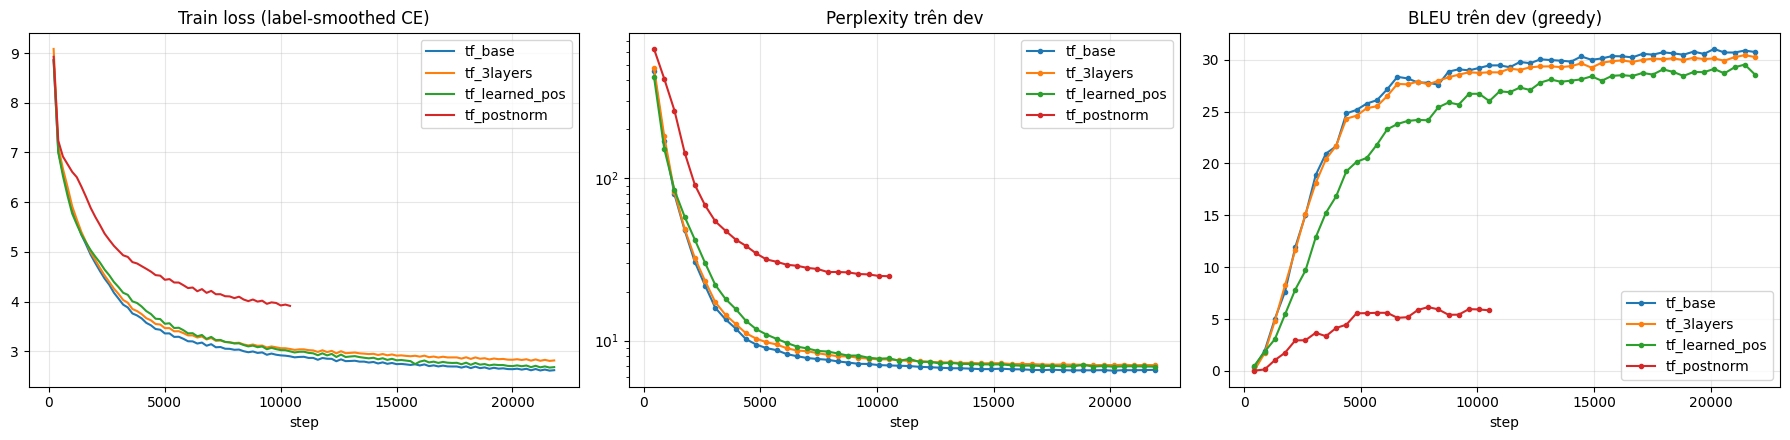

In [8]:
#@title 📈 Đường cong huấn luyện (loss, perplexity dev, BLEU dev)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name in EXPERIMENTS:
    f = paths.checkpoints / name / "history.csv"
    if not f.exists():
        continue
    h = pd.read_csv(f)
    tr = h.dropna(subset=["train_loss"]) if "train_loss" in h else h.iloc[0:0]
    ev = h.dropna(subset=["score"]) if "score" in h else h.iloc[0:0]
    ax[0].plot(tr["step"], tr["train_loss"], label=name)
    if "dev_ppl" in ev:
        ax[1].plot(ev["step"], ev["dev_ppl"], marker="o", ms=3, label=name)
    ax[2].plot(ev["step"], ev["score"], marker="o", ms=3, label=name)
ax[0].set(title="Train loss (label-smoothed CE)", xlabel="step"); ax[1].set(title="Perplexity trên dev", xlabel="step", yscale="log")
ax[2].set(title="BLEU trên dev (greedy)", xlabel="step")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(paths.figures / "02_learning_curves.png", dpi=150); plt.show()

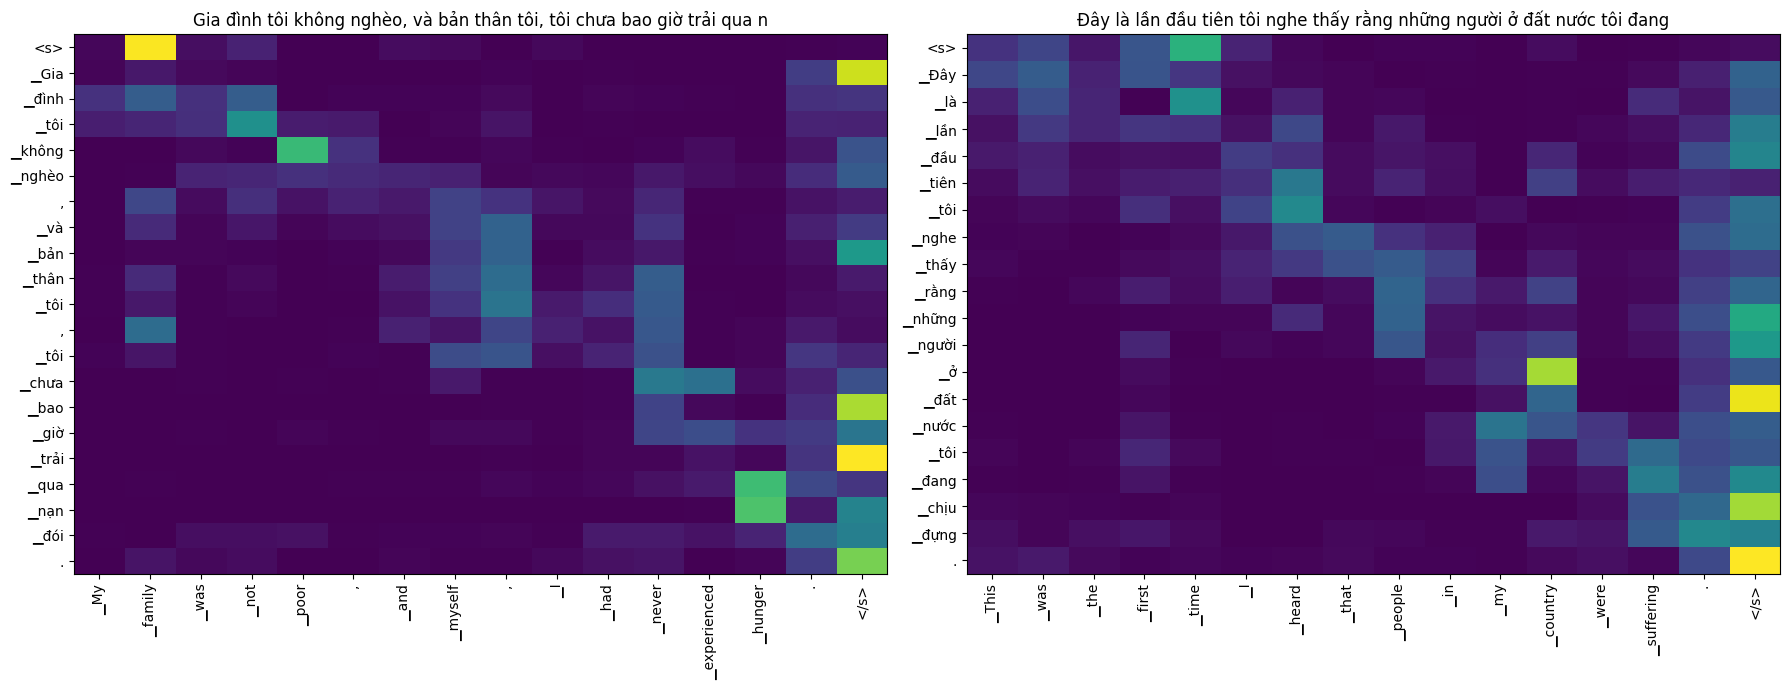

In [9]:
#@title 🔍 Trực quan hoá cross-attention (mô hình chính)
model, _ = build_model(EXPERIMENTS[MAIN])
best = torch.load(paths.checkpoints / MAIN / "best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(best["model"]); model.eval()
examples = [s for s in test_src_txt if 6 <= len(s.split()) <= 14][:2]
fig, axes = plt.subplots(1, len(examples), figsize=(9 * len(examples), 7))
axes = np.atleast_1d(axes)
for a, sent in zip(axes, examples):
    src = D.seq2seq_collate([(0, tok.encode([sent])[0], None)])["src"].to(DEVICE)
    hyp = DEC.seq2seq_generate_batch(model, src, beam_size=1)[0]
    tgt_in = torch.tensor([[D.BOS_ID] + hyp], device=DEVICE)
    with torch.no_grad():
        mem, ok = model.encode(src)
        model.decode(tgt_in, mem, ok, need_weights=True)
    w = model.decoder[-1].cross_attn.last_attn[0].mean(0).float().cpu().numpy()   # trung bình các head
    src_tok = [tok.sp.id_to_piece(i) for i in src[0].tolist()]
    tgt_tok = [tok.sp.id_to_piece(i) for i in [D.BOS_ID] + hyp]
    a.imshow(w, cmap="viridis", aspect="auto")
    a.set_xticks(range(len(src_tok))); a.set_xticklabels(src_tok, rotation=90)
    a.set_yticks(range(len(tgt_tok))); a.set_yticklabels(tgt_tok)
    a.set_title(tok.decode([hyp])[0][:70])
plt.tight_layout(); plt.savefig(paths.figures / "02_cross_attention.png", dpi=150); plt.show()
del model; free_memory()

In [10]:
#@title 📋 Tóm tắt
rows = []
for name, r in results.items():
    if r is None:
        continue
    for f in sorted(paths.predictions.glob(f"{name}_beam*.vi.txt")):
        system = f.name.replace(".vi.txt", "")
        meta = load_json(paths.predictions / f"{system}.meta.json")
        hyps = read_lines(f)
        rows.append({"hệ thống": system, "tham số (M)": round(r["params"] / 1e6, 1), "BLEU dev (greedy)": round(r["best_dev_bleu"], 2),
                     "BLEU test": round(M.quick_bleu(hyps, test_ref), 2), "beam": meta["beam"],
                     "thời gian train": fmt_seconds(r["train_time_s"]), "thời gian dịch (s)": round(meta["decode_time_s"], 1)})
df = pd.DataFrame(rows)
df.to_csv(paths.results / "02_table.csv", index=False)
print("Đánh giá đầy đủ (chrF++, TER, METEOR, COMET, BERTScore, kiểm định thống kê) ở notebook 06.")
df

Đánh giá đầy đủ (chrF++, TER, METEOR, COMET, BERTScore, kiểm định thống kê) ở notebook 06.


,hệ thống,tham số (M),BLEU dev (greedy),BLEU test,beam,thời gian train,thời gian dịch (s)
0,tf_base_beam1,39.7,31.04,30.57,1,1h07m07s,5.9
1,tf_base_beam2,39.7,31.04,30.93,2,1h07m07s,14.5
2,tf_base_beam4,39.7,31.04,31.41,4,1h07m07s,27.2
3,tf_base_beam8,39.7,31.04,31.47,8,1h07m07s,51.6
4,tf_3layers_beam4,24.0,30.44,30.46,4,45m53s,18.8
5,tf_learned_pos_beam4,40.0,29.53,29.74,4,1h08m28s,26.8
6,tf_postnorm_beam4,39.7,6.16,6.39,4,33m27s,29.4


✅ Xong. Tiếp theo: **03_gpt_decoder_only.ipynb** (có thể chạy song song trên một phiên Colab khác).